# Pluie de demain: session 1 checkpoint

Fill in this notebook during the session, run it on Kaggle, then hand in the `.ipynb` file on Moodle
(*File → Download notebook* on Kaggle). No grade: it is a checkpoint for your team.

**Team name:** Master Shifu

**Members:**
- Gabriel DESTAL
- Georg RIEKHAKAINEN
- Chris KARAM
- Liam SZEFNER

## 1. Set up (20 min)

Replace `[ ]` with `[x]` when done.

- [ ] Team of 3 to 4 formed, team name sent to the teaching team.
- [ ] Every member has joined the Kaggle competition of track 1 (*How much?*), and the team is merged on Kaggle. Track 2 (*Will it rain?*) opens later.
- [ ] This notebook runs on Kaggle with the competition data attached (*Add Input* if needed).

In [1]:
import os, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def find_data():
    hits = sorted(Path("/kaggle/input").glob("**/train.parquet"))
    if not hits:
        raise FileNotFoundError("train.parquet not found under /kaggle/input: add the competition data (Input panel)")
    return hits[0].parent

DATA = Path(os.environ.get("PDD_DATA") or find_data())
t0 = time.time()
train = pd.read_parquet(DATA / "train.parquet")
test = pd.read_parquet(DATA / "test.parquet")
maps = pd.read_parquet(DATA / "maps.parquet")
stations = pd.read_csv(DATA / "stations.csv", dtype={"station": str})
print(f"loaded in {time.time() - t0:.0f} s")

loaded in 1 s


## 2. Getting hold of the data (40 min)

In [2]:
#size of each file: rows, columns, memory, size on disk and load time
files = {"train": "train.parquet", "test": "test.parquet", "maps": "maps.parquet", "stations": "stations.csv"}
rows = []
for name, fname in files.items():
    t0 = time.time()
    df = pd.read_csv(DATA / fname, dtype={"station": str}) if fname.endswith(".csv") else pd.read_parquet(DATA / fname)
    rows.append({"file": fname, "rows": df.shape[0], "columns": df.shape[1],
                 "disk (MB)": (DATA / fname).stat().st_size / 1e6,
                 "memory (MB)": df.memory_usage(deep=True).sum() / 1e6,
                 "load (s)": time.time() - t0})
    del df
pd.DataFrame(rows).set_index("file").round(1)

,rows,columns,disk (MB),memory (MB),load (s)
file,,,,,
train.parquet,6888953,20,110.5,812.9,1.6
test.parquet,149108,19,2.3,17.0,0.2
maps.parquet,4838,334,2.2,6.5,0.0
stations.csv,1660,6,0.1,0.1,0.0


In [3]:
#what a row is, and how train and maps are joined
print("train: one row per (station, target_date), unique:", not train.duplicated(["station", "target_date"]).any())
print(f"  {train.station.nunique()} stations x {train.target_date.nunique()} days "
      f"({train.target_date.min():%Y-%m-%d} -> {train.target_date.max():%Y-%m-%d})")
print("maps: one row per target_date, unique:", maps.target_date.is_unique, f"({len(maps)} dates)")
groups = pd.Series([c.rsplit("_", 1)[0] for c in maps.columns[1:]]).value_counts()
print("  map variables x synoptic stations:", groups.to_dict())
print("  every train/test date has a map row:",
      train.target_date.isin(maps.target_date).all(), test.target_date.isin(maps.target_date).all())

#join train and maps for one station to see how many rows match
one = train[train.station == train.station.iloc[0]].merge(maps, on="target_date", how="left", validate="many_to_one")
print("  joined example:", one.shape)

#check the lags
s = train[train.station == train.station.iloc[0]].set_index("target_date")["rr"]
lagged = train[train.station == train.station.iloc[0]].set_index("target_date")
for k in (4, 10):
    match = np.isclose(lagged[f"rr_lag{k}"], s.shift(k, freq="D").reindex(lagged.index))
    print(f"rr_lag{k}(T) == rr(T-{k}): {np.nanmean(match):.1%} of days")

# check which day the map describes
obs = train.groupby("target_date")["rr"].mean()
map_rr = maps.set_index("target_date").filter(like="rr_day_").mean(axis=1)
corr = {f"T-{k}": map_rr.corr(obs.shift(k, freq="D").reindex(map_rr.index)) for k in range(0, 5)}
print("corr(map rain at row T, observed rain on day):", {k: round(float(v), 2) for k, v in corr.items()})

train: one row per (station, target_date), unique: True
  1457 stations x 4748 days (2010-01-01 -> 2022-12-31)
maps: one row per target_date, unique: True (4838 dates)
  map variables x synoptic stations: {'pmer': 37, 'dp24': 37, 't': 37, 'td': 37, 'u': 37, 'uw': 37, 'vw': 37, 'n': 37, 'rr_day': 37}
  every train/test date has a map row: True True
  joined example: (4748, 353)
rr_lag4(T) == rr(T-4): 99.9% of days
rr_lag10(T) == rr(T-10): 99.8% of days
corr(map rain at row T, observed rain on day): {'T-0': 0.2, 'T-1': 0.36, 'T-2': 0.87, 'T-3': 0.65, 'T-4': 0.26}


**What is a row of `train.parquet`? A row of `maps.parquet`? How are they joined?**

Answer: a row of `train.parquet` is one station on one day T (`id = station_YYYYMMDD`). It holds the target `rr`, the 24 h rainfall at that station on day T in mm, plus that station's past observations (`rr_lag4…10`, `tn/tx/ffm_lag4`) and its static metadata (lat, lon, alt, department, day of year, month). It has 6.9 M rows: 1,457 stations × 4,748 days (2010-01-01 to 2022-12-31). A row of `maps.parquet` is one day T for all of France. It holds 9 synoptic variables (`pmer`, `dp24`, `t`, `td`, `u`, `uw`, `vw`, `n`, `rr_day`) measured at 37 synoptic stations (WMO ids `07xxx`), so 333 columns. They are joined many-to-one on `target_date`: every station on day T gets the same map row.

**Which dates do a row's features come from, and why?**

Answer: for a target day T, the station features come from T−10 to T−4 (rain on each of those 7 days, temperature and wind on T−4 only). The map comes from **T−2**. The checks above confirm both: `rr_lagk(T)` equals the station's `rr` on day T−k, and the map's rain on row T correlates best with observed rain on T−2 (r ≈ 0.87, against 0.36 for T−1). The features only use what a forecaster would actually have when issuing the forecast. Daily records from the dense station network arrive with a delay of a few days (hence T−4 at best). The synoptic network is sent in near real time (hence T−2). Using anything closer to T would leak information that is unavailable in operation and inflate the validation score.

test stations: 1660, of which 203 never appear in train (12.2% of test rows)
all test stations are described in stations.csv: True
     n_stations  alt_median  dep_in_train
dep                                      
7            46       480.0         False
11           24       235.0         False
20           35       253.0         False
30           27       139.0         False
34           28       144.0         False
48           25       932.0         False
66           18       297.5         False
test dates: 90 days from 2023-01-20 to 2025-12-23, typical gap 12 days


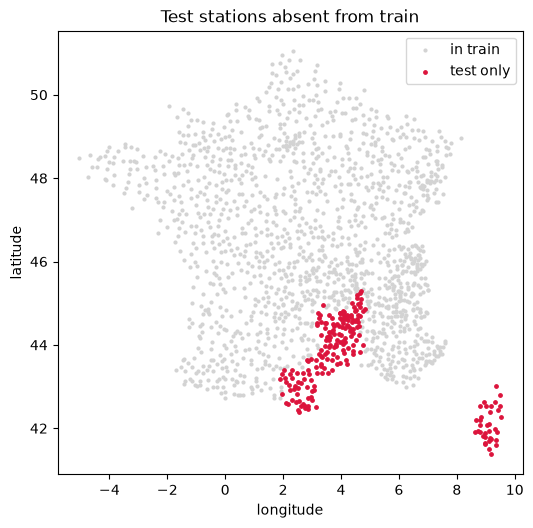

In [4]:
#stations of test.parquet absent from train.parquet
new = sorted(set(test.station) - set(train.station))
print(f"test stations: {test.station.nunique()}, of which {len(new)} never appear in train "
      f"({test.station.isin(new).mean():.1%} of test rows)")
print("all test stations are described in stations.csv:", set(test.station) <= set(stations.station))

new_st = stations[stations.station.isin(new)]
by_dep = new_st.groupby("dep").agg(n_stations=("station", "size"), alt_median=("alt", "median"))
by_dep["dep_in_train"] = by_dep.index.astype(str).str.zfill(2).isin(train.dep.unique())
print(by_dep)

#test dates
print(f"test dates: {test.target_date.nunique()} days from {test.target_date.min():%Y-%m-%d} to {test.target_date.max():%Y-%m-%d}, "
      f"typical gap {test.groupby('station').target_date.diff().mode()[0].days} days")

fig, ax = plt.subplots(figsize=(6, 6))
seen = stations[~stations.station.isin(new)]
ax.scatter(seen.lon, seen.lat, s=4, c="lightgrey", label="in train")
ax.scatter(new_st.lon, new_st.lat, s=6, c="crimson", label="test only")
ax.set(xlabel="longitude", ylabel="latitude", title="Test stations absent from train")
ax.set_aspect(1 / np.cos(np.radians(46)))
ax.legend()
plt.show()

**What did you find about the stations of the test set?**

Answer: the test set covers all 1,660 stations in `stations.csv`. 203 of them (12% of test rows) never appear in train. They are not scattered at random. They make up 7 entire departments that are missing from train: Ardèche (07), Aude (11), Corsica (20), Gard (30), Hérault (34), Lozère (48) and Pyrénées-Orientales (66). That is essentially the Mediterranean rim, the Cévennes and Corsica, the area of France with the heaviest and most intense autumn rain events ("épisodes cévenols"). So the test is a split in time (90 dates, one every 12 days, 2023-01-20 to 2025-12-23, all after the 2022 end of train) and in space. A model that relies on a station's identity or its learned climatology will have nothing for those stations. It must generalise from lat/lon/alt, the station's own lags and the map. Our validation should mimic this by holding out whole departments, not just later dates.

## 3. A first exploratory analysis (60 min)

Four figures, each followed by one sentence of conclusion.

{'dry (RR = 0)': 0.5, 'under 1 mm': 0.679}
rainy days quantiles (mm): {0.5: 2.0, 0.9: 13.4, 0.99: 36.2} max: 397.0


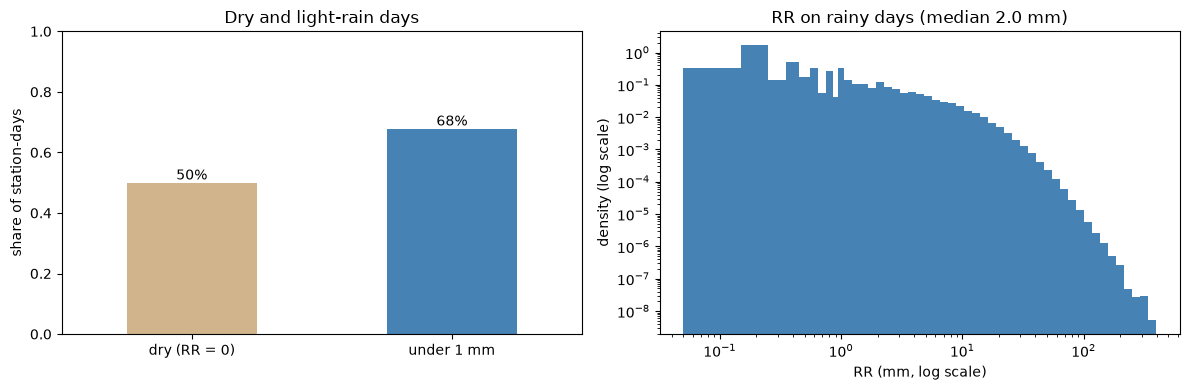

In [5]:
#Fig 1. The target: share of dry days (RR = 0), share of days under 1 mm, distribution of RR on rainy days (log scale)
rr = train["rr"]
shares = pd.Series({"dry (RR = 0)": (rr == 0).mean(), "under 1 mm": (rr < 1).mean()})
wet = rr[rr > 0]
print(shares.round(3).to_dict())
print("rainy days quantiles (mm):", wet.quantile([0.5, 0.9, 0.99]).round(1).to_dict(), "max:", wet.max())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
shares.plot.bar(ax=axes[0], color=["tan", "steelblue"], rot=0)
for i, v in enumerate(shares):
    axes[0].text(i, v + 0.01, f"{v:.0%}", ha="center")
axes[0].set(ylim=(0, 1), ylabel="share of station-days", title="Dry and light-rain days")

#gauges record in 0.1 mm steps, so bins of 0.1 mm under 1 mm and log bins above, density because widths differ
bins = np.r_[np.arange(0.05, 1, 0.1), np.logspace(np.log10(1.05), np.log10(wet.max()), 40)]
axes[1].hist(wet, bins=bins, density=True, color="steelblue")
axes[1].set(xscale="log", yscale="log", xlabel="RR (mm, log scale)", ylabel="density (log scale)",
            title=f"RR on rainy days (median {wet.median():.1f} mm)")
plt.tight_layout()
plt.show()

**Conclusion:** half of all station-days are completely dry and 68% get less than 1 mm, while amounts on rainy days are very skewed (median 2 mm, 99th percentile 36 mm, maximum 397 mm), which is why the target is split into rain or no rain plus an amount on a log scale, and scored with the RMSLE.

month          1      2      3      4      5      6      7      8      9   \
RR >= 1 mm  0.394  0.376  0.306  0.281  0.338  0.319  0.230  0.241  0.265   
RR > 0      0.585  0.550  0.452  0.426  0.493  0.468  0.371  0.406  0.466   

month          10     11     12  
RR >= 1 mm  0.313  0.388  0.409  
RR > 0      0.560  0.615  0.607  


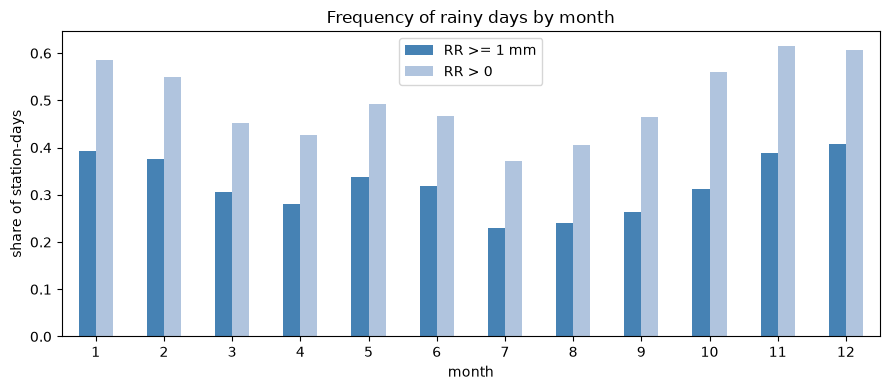

In [6]:
#Fig 2. Seasonality: frequency of rainy days by month
#rainy day = RR >= 1 mm (the usual Météo-France threshold), RR > 0 shown for comparison
by_month = pd.DataFrame({"RR >= 1 mm": (train.rr >= 1).groupby(train.month).mean(),
                         "RR > 0": (train.rr > 0).groupby(train.month).mean()})
print(by_month.round(3).T)

ax = by_month.plot.bar(figsize=(9, 4), color=["steelblue", "lightsteelblue"], rot=0)
ax.set(xlabel="month", ylabel="share of station-days", title="Frequency of rainy days by month")
plt.tight_layout()
plt.show()

**Conclusion:** rainy days follow a clear seasonal cycle, from about 40% of days (RR ≥ 1 mm) in December and January down to 23% in July, so the month or day of year is a useful feature, best encoded cyclically so that December sits next to January.

{'rainy': 1.0, 'lat': 0.45, 'lon': -0.36, 'alt': -0.02}
             rainy        lat       lon     alt
station                                        
13004003  0.146377  43.509998  4.693833     1.0
83069002  0.147251  43.000168  6.227167   143.0
13055001  0.148405  43.305668  5.394333    75.0
64316003  0.454881  43.033501 -1.033833  1427.0
29277001  0.463564  48.391335 -4.020500   157.0
29018001  0.474130  48.352669 -3.869000   220.0


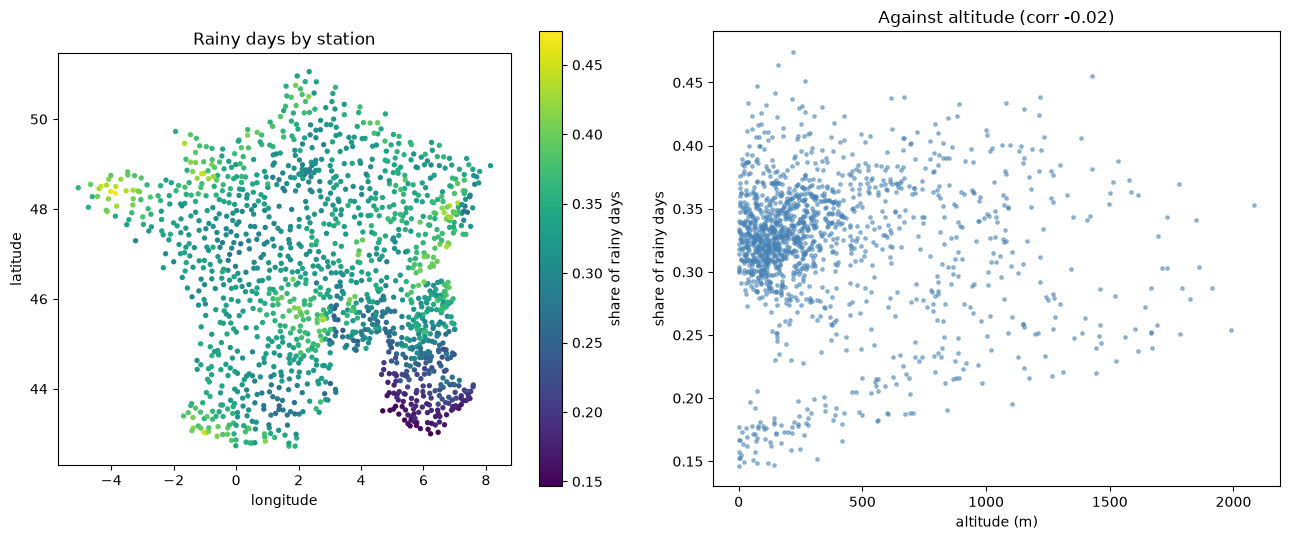

In [7]:
#Fig 3. Space: frequency of rainy days by station, against altitude or on a map (latitude/longitude)
#share of rainy days (RR >= 1 mm) per station
by_station = (train.assign(rainy=train.rr >= 1)
              .groupby("station")
              .agg(rainy=("rainy", "mean"), lat=("lat", "first"), lon=("lon", "first"), alt=("alt", "first")))
print(by_station[["rainy", "lat", "lon", "alt"]].corr()["rainy"].round(2).to_dict())
print(by_station.sort_values("rainy").iloc[[0, 1, 2, -3, -2, -1]])

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sc = axes[0].scatter(by_station.lon, by_station.lat, c=by_station.rainy, cmap="viridis", s=8)
fig.colorbar(sc, ax=axes[0], label="share of rainy days")
axes[0].set(xlabel="longitude", ylabel="latitude", title="Rainy days by station")
axes[0].set_aspect(1 / np.cos(np.radians(46)))

axes[1].scatter(by_station.alt, by_station.rainy, s=6, alpha=0.5, color="steelblue")
axes[1].set(xlabel="altitude (m)", ylabel="share of rainy days",
            title=f"Against altitude (corr {by_station.rainy.corr(by_station.alt):.2f})")
plt.tight_layout()
plt.show()

**Conclusion:** rain frequency depends on where the station is much more than on its altitude, going from 15% of days on the Provence coast to 47% in Brittany and the western Pyrenees (correlation 0.45 with latitude, −0.36 with longitude, about 0 with altitude), so lat/lon are worth keeping as features, and the train stations just east of the unseen Mediterranean departments, in Provence, are the driest of all.

{'rr_lag4': 0.0004, 'rr_lag5': 0.0005, 'rr_lag6': 0.0005, 'rr_lag7': 0.0006, 'rr_lag8': 0.0007, 'rr_lag9': 0.0007, 'rr_lag10': 0.0008, 'tn_lag4': 0.2061, 'tx_lag4': 0.2061, 'ffm_lag4': 0.626}
tx_lag4 missing in train vs test: 0.206 0.014
synoptic stations empty in all of 2025: ['07005', '07020', '07037', '07149', '07190', '07280', '07299', '07314', '07690']


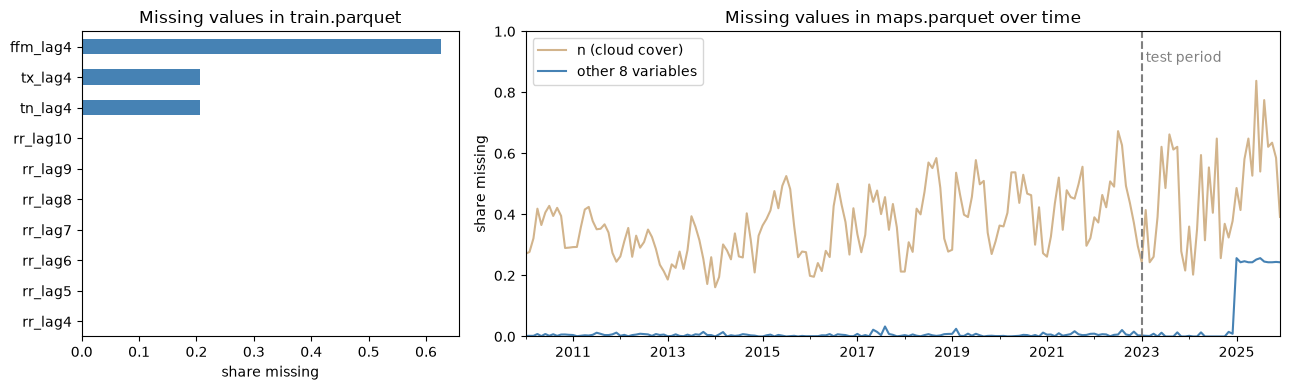

In [8]:
#Fog 4. Missing values: share of missing values per column of train.parquet, and of the map over time
#columns of train with at least one missing value
miss = train.isna().mean()
miss = miss[miss > 0].sort_values()
print(miss.round(4).to_dict())
print("tx_lag4 missing in train vs test:", round(train.tx_lag4.isna().mean(), 3), round(test.tx_lag4.isna().mean(), 3))

#share of missing map cells per month, cloud cover n apart from the other variables
map_miss = maps.set_index("target_date").isna()
by_var = map_miss.T.groupby(lambda c: c.rsplit("_", 1)[0]).mean().T
monthly = pd.DataFrame({"n (cloud cover)": by_var["n"],
                        "other 8 variables": by_var.drop(columns="n").mean(axis=1)}).resample("MS").mean()

#synoptic stations with no data at all in 2025
y2025 = map_miss[map_miss.index.year == 2025].filter(like="pmer_").mean()
print("synoptic stations empty in all of 2025:", sorted(c.split("_")[1] for c in y2025[y2025 == 1].index))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1, 2]})
miss.plot.barh(ax=axes[0], color="steelblue")
axes[0].set(xlabel="share missing", title="Missing values in train.parquet")

monthly.plot(ax=axes[1], color=["tan", "steelblue"])
axes[1].axvline(pd.Timestamp("2023-01-01"), color="grey", ls="--")
axes[1].text(pd.Timestamp("2023-02-01"), 0.9, "test period", color="grey")
axes[1].set(ylim=(0, 1), xlabel="", ylabel="share missing", title="Missing values in maps.parquet over time")
plt.tight_layout()
plt.show()

**Conclusion:** rain lags are almost complete, but ffm (wind) is missing for 63% of rows and tn/tx for 21% because many stations are rain gauges that never measure them (only 1.4% of test rows lack tn/tx, so the mix differs), and the map is almost complete in train (under 1% missing) apart from cloud cover n (around 37%), except on the 2025 test dates where 9 of the 37 synoptic stations disappear entirely, so imputation will matter more on the test set than in validation.

## 4. Stepping back on the starter (40 min)

Short answers, a few lines each.

**1. Which validation does it use, and why must days never be shuffled?**

Answer: it uses a split in time, training on earlier dates and validating on later ones, which matches the test set (2023 to 2025, all after train). Days must never be shuffled for three reasons. First, all stations on the same day share the same weather and the same map row, so with a random split the model sees station A on day T in train and station B on day T in validation, and simply learns that day's weather. Second, the lags overlap: rr_lag4 on day T+4 is the target of day T, so neighbouring days leak the answer. Third, the test is in the future, so a shuffled score would be far too optimistic and would not tell us anything about the leaderboard.

**2. Why combine the two models as exp(p·m1 + (1 − p)·m0) − 1 for the RMSLE, rather than p × predicted amount?**

Answer: the RMSLE is a mean squared error on log1p(RR), so the best prediction is exp(E[log1p(RR)]) − 1, the mean on the log scale brought back to mm. If m1 and m0 predict log1p(RR) on rainy days (RR ≥ 1 mm) and on the other days, then E[log1p(RR)] = p·m1 + (1 − p)·m0, which gives the formula. p × predicted amount is the mean in mm, which is what you would want for an RMSE, but because the log is concave it is too high on the log scale, and it also ignores the drizzle under 1 mm that m0 covers. With the averages from train (log1p is 1.82 on rainy days and 0.07 on the others, 7.6 mm on average when it rains) and p = 0.3, the formula gives 0.8 mm while p × amount gives 2.3 mm, which the RMSLE would penalise heavily on the many dry days.

**3. Its PCA keeps 20 components: is that justified? What does the median imputation do when map columns are empty?**

Answer: only partly. The 333 map columns are very correlated (the same pressure or wind field seen by 37 stations), so a few components capture the large-scale weather pattern. But 20 components only keep about 72% of the variance (90% would need 86), and the number looks arbitrary: PCA keeps what varies most, not what predicts rain best, so it should be tuned on the validation score. The median imputation replaces every missing value by the training median, so an empty station looks like a station reporting perfectly average weather, and after scaling it pushes its part of the components towards zero. Two cloud cover columns (n_07005 and n_07558) are empty for the whole train period, so they have no median at all. And on the 2025 test dates, 84 of the 333 columns (9 stations) are always empty, so the components are computed on partly fake data that the model never saw in validation.

**4. How does it predict a station it has never seen?**

Answer: in the same way as any other station, because it does not use the station identifier: it only looks at the station's own lags, its lat/lon/alt, the day of the year and the map, and all of these exist for a new station. So it treats the new station as a new point in feature space. The problem is that the 203 new stations are whole Mediterranean departments: 35 of them (Corsica) lie east of the easternmost train station and 48 lie south of the southernmost one, where tree models just copy the nearest edge of the training data, and their climate (rarer but heavier rain) is not well represented in train.

**5. Is its Brier score good? Compared with what?**

Answer: a Brier score only means something against a reference. Always predicting the rain rate of train (0.321, which is exactly sample_submission_rain.csv) gives 0.321 × 0.679 ≈ 0.218. On 2022 held out, the rain rate of the earlier years gives 0.200, the rate by month 0.198 and the rate by station and month 0.196. The starter scores … , so its skill score 1 − Brier / Brier_reference is … against the best of these. Since its features stop at T−4 for the stations and T−2 for the map, a gain of a few percent over climatology is what we can realistically expect, so it is only good if it beats the station and month rate, not just the constant.

## 5. Plan (20 min)

- [ ] A first submission in track 1 (the starter's `submission.csv` is fine). Public score obtained: …

**Three things to try next, and who does what:**

1. … (who: …)
2. … (who: …)
3. … (who: …)